# Лабораторная работа 2. Текстовое ранжирование: TF-IDF и BM25 на WikiQA
## Шаблон студента

**ФИО:** Чаговец Валерия Ярославовна
**Группа:** ИНФА-231
**Вариант:** 15

---

**Цель работы:** освоить построение и сравнение классических алгоритмов текстового
ранжирования TF-IDF и BM25 на англоязычном корпусе, научиться вычислять DCG/NDCG
и интерпретировать причины различий поисковой выдачи.

**Постановка задачи.** Для английского вопроса требуется расположить предложения
связанной статьи Wikipedia так, чтобы предложения, содержащие правильный ответ,
оказались как можно выше в выдаче.

**Как работать с ноутбуком**

1. Ячейки с пометкой `# ВЫДАНО` менять не нужно — это инфраструктура.
2. Ячейки с `# TODO` содержат задания. Каждое задание закрывается автотестом
   (`test_*`): пока задание не выполнено, тест падает.
3. В конце есть ячейка «Полная самопроверка» — перед сдачей она должна пройти целиком.
4. Перед сдачей выполните **Kernel → Restart & Run All**: ноутбук обязан
   воспроизводиться сверху вниз без ручных правок.

**Что нельзя делать**

* использовать колонку `Label` при вычислении оценок ранжирования (это утечка
  разметки; автотест её обнаруживает);
* строить индекс только по кандидатам одного вопроса — IDF и средняя длина документа
  считаются по всему выбранному split;
* использовать разную токенизацию для TF-IDF и BM25.

## 1. Настройка окружения и вариант

In [1]:
# ВЫДАНО: установка зависимостей и импорты
import importlib
import re
import subprocess
import sys
import warnings
import zlib

def ensure(packages):
    for module, pip_name in packages.items():
        try:
            importlib.import_module(module)
        except ImportError:
            print(f"[install] {pip_name} ...")
            try:
                subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name],
                               check=True, timeout=300)
            except Exception as exc:                  # noqa: BLE001
                print(f"[warn] не удалось установить {pip_name}: {exc}")

ensure({"rank_bm25": "rank-bm25", "sklearn": "scikit-learn",
        "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib"})
ensure({"kagglehub": "kagglehub"})

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import ndcg_score

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
warnings.filterwarnings("ignore", category=FutureWarning)
print("Окружение готово. Python", sys.version.split()[0])

Окружение готово. Python 3.13.18


In [2]:
# ВЫДАНО: параметры индивидуального варианта
B_GRID = [0.60, 0.70, 0.75, 0.80, 0.85]

def get_variant(v: int) -> dict:
    if not 1 <= int(v) <= 25:
        raise ValueError("Номер варианта должен быть в диапазоне 1..25")
    v = int(v)
    return {"variant": v,
            "k1": round(1.2 + 0.2 * ((v - 1) // 5), 1),
            "b": B_GRID[(v - 1) % 5],
            "k": 5 if v % 2 == 1 else 10}

# ------------------------------------------------------------------
VARIANT = 15        # <-- ЗАМЕНИТЕ на номер своего варианта (1..25)
# ------------------------------------------------------------------
PARAMS = get_variant(VARIANT)
K1, B, K = PARAMS["k1"], PARAMS["b"], PARAMS["k"]
print(f"Вариант {VARIANT}: k1 = {K1}, b = {B}, метрика NDCG@{K}")

Вариант 15: k1 = 1.6, b = 0.85, метрика NDCG@5


## 2. Данные: Microsoft Research WikiQA Corpus

Единица **документа** в этой работе — одно предложение-кандидат (`Sentence`),
**запрос** — англоязычный вопрос (`Question`), **истинная релевантность** — `Label` (0/1).

Схема исходного TSV-файла:

| Поле | Смысл |
|---|---|
| `QuestionID` | идентификатор вопроса (`Q1`, `Q2`, …) |
| `Question` | текст вопроса на английском языке |
| `DocumentID`, `DocumentTitle` | статья Wikipedia, из которой взяты кандидаты |
| `SentenceID` | идентификатор предложения-кандидата |
| `Sentence` | текст предложения-кандидата |
| `Label` | 1 — предложение является ответом, 0 — не является |

Ячейка ниже реализует **три пути загрузки** (выполняются по очереди, до первого успешного):

1. локальный файл `data/wikiqa/WikiQA-test.tsv` (скачан вручную с Microsoft Download Center или с Kaggle);
2. автоматическая загрузка через `kagglehub` (зеркало `saurabhshahane/wikiqa-corpus`) или через `datasets` (`microsoft/wiki_qa`);
3. **синтетический генератор-заглушка** — на случай, когда сети нет вообще.

> ⚠️ Третий путь нужен только для того, чтобы ноутбук гарантированно запускался и код можно было отладить.
> Числа, полученные на синтетических данных, **не являются** результатом лабораторной работы:
> сдавать нужно прогон на настоящем WikiQA (переменная `DATA_SOURCE` должна быть `local`, `kagglehub` или `huggingface`).

In [3]:
# ============================================================================
#  Загрузка WikiQA: три пути (локальный файл -> сеть -> синтетическая заглушка)
# ============================================================================
import os
import glob
import random
import warnings

import numpy as np
import pandas as pd

WIKIQA_COLUMNS = ["QuestionID", "Question", "DocumentID", "DocumentTitle",
                  "SentenceID", "Sentence", "Label"]

# Справочные размеры настоящего корпуса (Yang, Yih, Meek, EMNLP 2015)
WIKIQA_REFERENCE = {
    "train": {"questions": 2118, "sentences": 20360, "answers": 1040},
    "dev":   {"questions": 296,  "sentences": 2733,  "answers": 140},
    "test":  {"questions": 633,  "sentences": 6165,  "answers": 293},
}

DATA_SOURCE = None  # заполняется функцией load_wikiqa()


def _normalize(df):
    """Приводит датафрейм к каноническому набору колонок WIKIQA_COLUMNS."""
    df = df.copy()
    rename = {"question_id": "QuestionID", "question": "Question",
              "document_title": "DocumentTitle", "answer": "Sentence",
              "label": "Label", "sentence": "Sentence"}
    df = df.rename(columns={c: rename[c] for c in df.columns if c in rename})
    if "DocumentID" not in df.columns:
        df["DocumentID"] = df.get("DocumentTitle", pd.Series(["D0"] * len(df)))
    if "SentenceID" not in df.columns:
        df["SentenceID"] = [f"{q}-{i}" for i, q in enumerate(df["QuestionID"])]
    df["Label"] = df["Label"].astype(int)
    for col in ("Question", "Sentence", "DocumentTitle"):
        df[col] = df[col].astype(str)
    return df[WIKIQA_COLUMNS].reset_index(drop=True)


def _load_local(split, data_dir):
    """Путь 1. Локальный TSV-файл из официального архива WikiQACorpus."""
    patterns = [
        os.path.join(data_dir, f"WikiQA-{split}.tsv"),
        os.path.join(data_dir, "**", f"WikiQA-{split}.tsv"),
        os.path.join("**", f"WikiQA-{split}.tsv"),
    ]
    for pattern in patterns:
        hits = sorted(glob.glob(pattern, recursive=True))
        if hits:
            return _normalize(pd.read_csv(hits[0], sep="\t", quoting=3)), hits[0]
    return None, None


def _load_kagglehub(split):
    """Путь 2а. Kaggle-зеркало (kagglehub скачивает архив в локальный кэш)."""
    import kagglehub
    path = kagglehub.dataset_download("saurabhshahane/wikiqa-corpus")
    hits = sorted(glob.glob(os.path.join(path, "**", f"WikiQA-{split}.tsv"),
                            recursive=True))
    if not hits:
        raise FileNotFoundError(f"WikiQA-{split}.tsv не найден в {path}")
    return _normalize(pd.read_csv(hits[0], sep="\t", quoting=3)), hits[0]


def _load_huggingface(split):
    """Путь 2б. Hugging Face Hub: microsoft/wiki_qa."""
    from datasets import load_dataset
    hf_split = {"dev": "validation"}.get(split, split)
    ds = load_dataset("microsoft/wiki_qa", split=hf_split)
    return _normalize(ds.to_pandas()), "huggingface:microsoft/wiki_qa"


# ---------------------------------------------------------------------------
#  Путь 3. Синтетическая заглушка, имитирующая структуру и статистику WikiQA
# ---------------------------------------------------------------------------
_SYN_TOPICS = [
    ("Glacier cave", ["glacier", "meltwater", "crevasse", "ice", "tunnel"]),
    ("Harpsichord", ["keyboard", "plectrum", "strings", "baroque", "jack"]),
    ("Monsoon", ["rainfall", "wind", "seasonal", "tropics", "humidity"]),
    ("Lighthouse", ["beacon", "coast", "lantern", "keeper", "navigation"]),
    ("Penicillin", ["antibiotic", "mould", "bacteria", "infection", "culture"]),
    ("Sundial", ["gnomon", "shadow", "hours", "dial", "solar"]),
    ("Aqueduct", ["channel", "water", "arches", "roman", "gradient"]),
    ("Kiwi bird", ["flightless", "burrow", "nocturnal", "beak", "forest"]),
    ("Tundra", ["permafrost", "arctic", "lichen", "shrub", "soil"]),
    ("Zeppelin", ["airship", "hydrogen", "rigid", "hull", "flight"]),
    ("Sonar", ["acoustic", "echo", "submarine", "pulse", "underwater"]),
    ("Kimchi", ["fermented", "cabbage", "korean", "chilli", "jar"]),
    ("Obsidian", ["volcanic", "glass", "lava", "fracture", "blade"]),
    ("Morse code", ["telegraph", "dots", "dashes", "signal", "operator"]),
    ("Coral reef", ["polyp", "calcium", "lagoon", "tropical", "bleaching"]),
    ("Windmill", ["sails", "grain", "milling", "rotor", "tower"]),
    ("Vaccine", ["immunity", "antigen", "dose", "clinical", "virus"]),
    ("Cuneiform", ["clay", "tablet", "stylus", "sumerian", "script"]),
    ("Geyser", ["eruption", "groundwater", "steam", "vent", "basin"]),
    ("Espresso", ["pressure", "portafilter", "crema", "roast", "grind"]),
    ("Bagpipes", ["drone", "chanter", "reed", "highland", "bag"]),
    ("Permaculture", ["agriculture", "design", "guild", "mulch", "yield"]),
    ("Semaphore", ["flags", "visual", "signalling", "arms", "station"]),
    ("Plate tectonics", ["lithosphere", "subduction", "mantle", "drift", "fault"]),
    ("Origami", ["folding", "paper", "crease", "model", "japanese"]),
    ("Quinine", ["malaria", "bark", "alkaloid", "tonic", "treatment"]),
    ("Lacrosse", ["stick", "netting", "team", "goal", "field"]),
    ("Pidgin language", ["contact", "grammar", "trade", "speakers", "simplified"]),
    ("Cartography", ["projection", "scale", "map", "survey", "legend"]),
    ("Hovercraft", ["cushion", "skirt", "fan", "amphibious", "craft"]),
]

_SYN_ASPECTS = [
    ("origin", "how is the {f} of a {t} formed", ["formed", "formation", "forms"],
     ["arises", "develops", "emerges"]),
    ("definition", "what is the {f} of {t}", ["term", "refers", "defined"],
     ["denotes", "describes", "means"]),
    ("location", "where is the {f} of {t} found", ["located", "situated", "region"],
     ["lies", "occurs", "distributed"]),
    ("time", "when was the {f} of {t} first described", ["first", "described", "century"],
     ["initially", "documented", "recorded"]),
    ("person", "who invented the {t} {f}", ["invented", "inventor", "engineer"],
     ["devised", "pioneer", "credited"]),
    ("size", "how big is the {f} of a {t}", ["metres", "diameter", "large"],
     ["measures", "span", "extent"]),
    ("purpose", "what is the {f} of {t} used for", ["used", "purpose", "application"],
     ["serves", "employed", "role"]),
    ("cause", "what causes the {f} of {t}", ["caused", "cause", "results"],
     ["triggered", "produced", "driven"]),
]

_SYN_FILLER = (
    "the of and in to a is was for with on as by are from that at it this "
    "which or an be were has have been also often usually most many some "
    "such other than more into between during after before over under "
    "modern early late common known called including example although "
    "however typically generally particularly widely small large narrow "
    "wide long short heavy light natural artificial local regional "
    "surface material structure system process design method number "
    "period record study report century year time part group area"
).split()


def _syn_sentence(rng, title_tokens, topic_words, cues, length):
    """Собирает предложение заданной длины из тематических и служебных слов."""
    tokens = list(title_tokens) + list(topic_words) + list(cues)
    while len(tokens) < length:
        # частотный «хвост»: короткие служебные слова встречаются чаще
        idx = min(int(abs(rng.gauss(0, 0.35)) * len(_SYN_FILLER)), len(_SYN_FILLER) - 1)
        tokens.append(_SYN_FILLER[idx])
    rng.shuffle(tokens)
    text = " ".join(tokens)
    return text[0].upper() + text[1:] + " ."


def _load_synthetic(split, seed=20261014):
    """Путь 3. Детерминированная имитация WikiQA со схожей статистикой."""
    ref = WIKIQA_REFERENCE.get(split, WIKIQA_REFERENCE["test"])
    n_questions = ref["questions"]
    rng = random.Random(seed + len(split))
    rows = []
    for qi in range(n_questions):
        title, topic_vocab = _SYN_TOPICS[rng.randrange(len(_SYN_TOPICS))]
        aspect, tmpl, cues, syn_cues = _SYN_ASPECTS[rng.randrange(len(_SYN_ASPECTS))]
        title_tokens = title.lower().split()
        focus = rng.choice(topic_vocab)               # содержательное слово вопроса
        others = [w for w in topic_vocab if w != focus]
        question = tmpl.format(t=title.lower(), f=focus)
        # доля вопросов без единого правильного ответа ~ как в настоящем WikiQA
        has_answer = rng.random() < (243 / 633)
        n_cand = max(2, int(rng.gauss(9.7, 3.5)))
        n_pos = rng.randint(1, 2) if has_answer else 0
        pos_slots = set(rng.sample(range(n_cand), k=min(n_pos, n_cand)))
        # четверть правильных ответов выражена синонимами, а не словами вопроса
        paraphrase = rng.random() < 0.25
        for si in range(n_cand):
            topic_words = rng.sample(others, k=min(len(others), rng.randint(1, 3)))
            if si in pos_slots:
                label = 1
                if paraphrase:                        # лексический разрыв
                    sent_cues = rng.sample(syn_cues, k=min(2, len(syn_cues)))
                else:
                    sent_cues = rng.sample(cues, k=min(2, len(cues))) + [focus]
            else:
                label = 0
                sent_cues = []
                if rng.random() < 0.30:               # «трудный» отрицательный
                    sent_cues.append(rng.choice(cues))
                if rng.random() < 0.25:
                    sent_cues.append(focus)
                if rng.random() < 0.12:               # «переспам»: слово вопроса 2-4 раза
                    sent_cues += [focus] * rng.randint(2, 4)
            length = max(6, int(rng.gauss(25, 11)))   # средняя длина ~25 токенов
            rows.append({
                "QuestionID": f"S{qi + 1}",
                "Question": question,
                "DocumentID": f"D{qi + 1}",
                "DocumentTitle": title,
                "SentenceID": f"S{qi + 1}-{si}",
                "Sentence": _syn_sentence(rng, title_tokens, topic_words,
                                          sent_cues, length),
                "Label": label,
            })
    return _normalize(pd.DataFrame(rows)), "synthetic"


def load_wikiqa(split="test", data_dir="data/wikiqa", allow_synthetic=True,
                verbose=True):
    """Возвращает (DataFrame, источник). Порядок: локально -> сеть -> заглушка."""
    global DATA_SOURCE
    attempts = [
        ("local", lambda: _load_local(split, data_dir)),
        ("kagglehub", lambda: _load_kagglehub(split)),
        ("huggingface", lambda: _load_huggingface(split)),
    ]
    for name, fn in attempts:
        try:
            df, origin = fn()
            if df is not None and len(df) > 0:
                DATA_SOURCE = name
                if verbose:
                    print(f"[OK] Источник данных: {name} ({origin})")
                return df, name
        except Exception as exc:                      # noqa: BLE001
            if verbose:
                print(f"[--] {name}: {type(exc).__name__}: {exc}")
    if not allow_synthetic:
        raise RuntimeError(
            "Настоящий WikiQA не найден. Скачайте WikiQACorpus.zip и положите "
            "WikiQA-test.tsv в data/wikiqa/, либо установите kagglehub/datasets."
        )
    df, _ = _load_synthetic(split)
    DATA_SOURCE = "synthetic"
    warnings.warn("Используется СИНТЕТИЧЕСКАЯ заглушка: результаты не засчитываются "
                  "как выполнение лабораторной работы.", stacklevel=2)
    if verbose:
        print("[!!] Источник данных: synthetic (заглушка, только для отладки кода)")
    return df, "synthetic"


def describe_corpus(df, split="test"):
    """Печатает статистику загруженного корпуса и сверяет её со справочной."""
    n_q = df["QuestionID"].nunique()
    n_s = len(df)
    n_a = int(df["Label"].sum())
    per_q = df.groupby("QuestionID")["Label"].agg(["size", "sum"])
    n_q_with_answer = int((per_q["sum"] > 0).sum())
    print(f"Вопросов:                      {n_q}")
    print(f"Предложений-кандидатов:        {n_s}")
    print(f"Предложений с Label=1:         {n_a}")
    print(f"Вопросов, где есть ответ:      {n_q_with_answer} "
          f"({n_q_with_answer / max(n_q, 1):.1%})")
    print(f"Кандидатов на вопрос (сред.):  {per_q['size'].mean():.2f} "
          f"[{per_q['size'].min()}..{per_q['size'].max()}]")
    print(f"Длина предложения (токенов):   "
          f"{df['Sentence'].str.split().str.len().mean():.2f}")
    ref = WIKIQA_REFERENCE.get(split)
    if ref:
        ok = (n_q == ref["questions"] and n_s == ref["sentences"]
              and n_a == ref["answers"])
        print(f"\nСправочные значения WikiQA-{split}: "
              f"{ref['questions']} вопросов / {ref['sentences']} предложений / "
              f"{ref['answers']} ответов")
        print("Совпадение со справочными значениями:", "ДА" if ok else "НЕТ")
    return per_q

In [4]:
# ВЫДАНО: загрузка корпуса и базовая статистика
SPLIT = "test"
df, source = load_wikiqa(split=SPLIT, data_dir="data/wikiqa", allow_synthetic=True)
df = df.reset_index(drop=True)
describe_corpus(df, split=SPLIT)
df.head(5)

100%|██████████| 6.75M/6.75M [00:00<00:00, 38.9MB/s]

Extracting files...


[OK] Источник данных: kagglehub (/root/.cache/kagglehub/datasets/saurabhshahane/wikiqa-corpus/versions/1/WikiQA-test.tsv)
Вопросов:                      633
Предложений-кандидатов:        6165
Предложений с Label=1:         293
Вопросов, где есть ответ:      243 (38.4%)
Кандидатов на вопрос (сред.):  9.74 [1..30]
Длина предложения (токенов):   22.42

Справочные значения WikiQA-test: 633 вопросов / 6165 предложений / 293 ответов
Совпадение со справочными значениями: ДА


,QuestionID,Question,DocumentID,DocumentTitle,SentenceID,Sentence,Label
0,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-0,African immigration to the United States refers to immigrants to the United States who...,0
1,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-1,The term African in the scope of this article refers to geographical or national origi...,0
2,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-2,"From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to...",0
3,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-3,African immigrants in the United States come from almost all regions in Africa and do ...,0
4,Q0,HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US,D0,African immigration to the United States,D0-4,"They include people from different national, linguistic, ethnic, racial, cultural and ...",0


## 2. Задание 1. Исследование candidate sets

Ответьте на вопросы (числами, полученными из данных, а не из README):

1. Сколько всего вопросов и сколько предложений-кандидатов в загруженном split?
2. У какой доли вопросов есть хотя бы одно предложение с `Label = 1`?
3. Каково среднее число кандидатов на вопрос и средняя длина предложения?
4. Выведите все кандидаты одного вопроса, у которого есть правильный ответ,
   и пометьте правильные предложения.

Почему это важно: все кандидаты одного вопроса взяты из одной и той же статьи
Wikipedia, поэтому слова из заголовка статьи почти не различают кандидатов.

Всего вопросов:                 633
Вопросов с ответом (eligible):  243 (38.4%)
Правильных ответов на вопрос:   1.21 (макс. 4)
Доля Label=1 среди кандидатов:  4.75%

Распределение числа кандидатов:
count    633.00
mean       9.74
std        6.38
min        1.00
25%        5.00
50%        8.00
75%       13.00
max       30.00


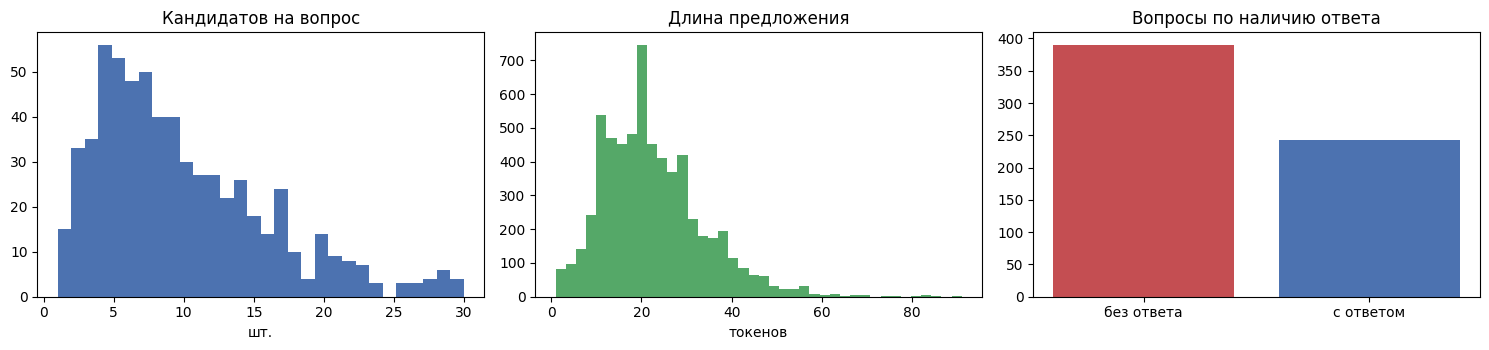


Пример: Q0 — «HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US» (страница: African immigration to the United States)
         African immigration to the United States refers to immigrants to the United States who are or were nationals o
         The term African in the scope of this article refers to geographical or national origins rather than racial af
         From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to 0.9 million Africans im
         African immigrants in the United States come from almost all regions in Africa and do not constitute a homogen
         They include people from different national, linguistic, ethnic, racial, cultural and social backgrounds.
 [ОТВЕТ] As such, African immigrants are to be distinguished from African American people, the latter of whom are desce


In [5]:
stats = df.groupby("QuestionID").agg(
    n_candidates=("SentenceID", "size"),
    n_positive=("Label", "sum"),
    question=("Question", "first"),
    title=("DocumentTitle", "first"),
)
eligible = stats[stats["n_positive"] > 0]

print(f"Всего вопросов:                 {len(stats)}")
print(f"Вопросов с ответом (eligible):  {len(eligible)} ({len(eligible)/len(stats):.1%})")
print(f"Правильных ответов на вопрос:   {eligible['n_positive'].mean():.2f} "
      f"(макс. {int(eligible['n_positive'].max())})")
print(f"Доля Label=1 среди кандидатов:  {df['Label'].mean():.2%}")
print("\nРаспределение числа кандидатов:")
print(stats["n_candidates"].describe().round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].hist(stats["n_candidates"], bins=30, color="#4C72B0")
axes[0].set_title("Кандидатов на вопрос"); axes[0].set_xlabel("шт.")
axes[1].hist(df["Sentence"].str.split().str.len(), bins=40, color="#55A868")
axes[1].set_title("Длина предложения"); axes[1].set_xlabel("токенов")
axes[2].bar(["без ответа", "с ответом"],
            [len(stats) - len(eligible), len(eligible)], color=["#C44E52", "#4C72B0"])
axes[2].set_title("Вопросы по наличию ответа")
plt.tight_layout(); plt.show()

# пример одного candidate set
demo_qid = eligible.index[0]
demo = df[df["QuestionID"] == demo_qid]
print(f"\nПример: {demo_qid} — «{demo['Question'].iloc[0]}» "
      f"(страница: {demo['DocumentTitle'].iloc[0]})")
for _, row in demo.iterrows():
    mark = "[ОТВЕТ]" if row["Label"] == 1 else "       "
    print(f" {mark} {row['Sentence'][:110]}")

## 3. Задание 2. Единая токенизация

`rank_bm25` **не выполняет предобработку самостоятельно**: запрос нужно обрабатывать
точно так же, как документы. Поэтому напишем один токенизатор и будем передавать его
и в `TfidfVectorizer` (через параметр `analyzer`), и в BM25.

Требования к `tokenize`:

* приводит текст к нижнему регистру;
* оставляет только последовательности букв и цифр (пунктуация отбрасывается);
* при `remove_stopwords=True` убирает английские стоп-слова из `ENGLISH_STOPWORDS`
  (вопросительные слова *how, what, when, who* в этот список намеренно **не** включены —
  посмотрите в разборе запросов, помогают они или мешают);
* возвращает **список** токенов.

In [6]:
# ВЫДАНО: список стоп-слов и заготовка регулярного выражения
TOKEN_RE = re.compile(r"[a-z0-9]+")

ENGLISH_STOPWORDS = frozenset("""
a an the and or but if then than that this these those there here of in on at to
for with without within from by as is are was were be been being am do does did
doing have has had having will would shall should can could may might must
it its it's he she they them his her their our your my me we you i not no nor so
such about into over under again further once during before after above below
""".split())


def light_stem(token: str) -> str:
    """Очень простой суффиксный стеммер (демонстрационный, не Porter)."""
    for suffix, repl in (("sses", "ss"), ("ies", "y"), ("ing", ""), ("ed", "")):
        if token.endswith(suffix) and len(token) - len(suffix) >= 4:
            return token[: len(token) - len(suffix)] + repl
    if token.endswith("s") and not token.endswith("ss") and len(token) > 3:
        return token[:-1]
    return token


def tokenize(text, remove_stopwords: bool = True, stem: bool = False):
    """Приводит текст к списку токенов. Используется и для документов, и для запросов."""
    tokens = TOKEN_RE.findall(str(text).lower())
    if remove_stopwords:
        tokens = [t for t in tokens if t not in ENGLISH_STOPWORDS]
    if stem:
        tokens = [light_stem(t) for t in tokens]
    return tokens


def make_tokenizer(remove_stopwords=True, stem=False):
    """Фабрика токенизаторов: передаётся и в TfidfVectorizer, и в BM25."""
    def _tok(text):
        return tokenize(text, remove_stopwords=remove_stopwords, stem=stem)
    return _tok


TOKENIZER = make_tokenizer(remove_stopwords=True, stem=False)

In [7]:
# ВЫДАНО: автотест задания 2
def test_tokenize():
    assert tokenize("The Glacier Caves were formed!") == ["glacier", "caves", "formed"], \
        "проверьте нижний регистр, пунктуацию и удаление стоп-слов"
    assert tokenize("The 1889 Paris Exposition!") == ["1889", "paris", "exposition"], \
        "цифры должны сохраняться"
    assert tokenize("the of and in to") == [], "стоп-слова должны удаляться"
    assert tokenize("The of and", remove_stopwords=False) == ["the", "of", "and"], \
        "при remove_stopwords=False стоп-слова остаются"
    assert isinstance(tokenize("test"), list), "функция должна возвращать список"
    assert TOKENIZER("A lighthouse.") == tokenize("A lighthouse."), \
        "TOKENIZER должен совпадать с tokenize"
    print("test_tokenize: OK")

test_tokenize()

test_tokenize: OK


## 4. Задание 3. TF-IDF

`TfidfVectorizer` строит матрицу «документ × терм». При `norm="l2"` строки нормированы,
поэтому скалярное произведение вектора вопроса и вектора предложения равно косинусной
близости:

$$\cos(q,d)=\frac{\langle q,d\rangle}{\lVert q\rVert\lVert d\rVert}=\langle\hat q,\hat d\rangle$$

**Важно:** индекс строится по **всем** предложениям split (чтобы IDF был
общекорпусным), а ранжируются только кандидаты конкретного вопроса.

In [8]:
# TODO 3: постройте индекс TF-IDF и функцию оценки
SENTENCES = df["Sentence"].tolist()

tfidf_vectorizer = TfidfVectorizer(analyzer=TOKENIZER, norm="l2", sublinear_tf=False)
TFIDF_MATRIX = tfidf_vectorizer.fit_transform(SENTENCES)
print(f"Матрица TF-IDF: {TFIDF_MATRIX.shape[0]} документов x "
      f"{TFIDF_MATRIX.shape[1]} термов, заполненность "
      f"{TFIDF_MATRIX.nnz / (TFIDF_MATRIX.shape[0] * TFIDF_MATRIX.shape[1]):.4%}")


def tfidf_scorer(question, candidate_idx):
    """Косинусная близость вопроса и кандидатов (оба вектора L2-нормированы)."""
    q_vec = tfidf_vectorizer.transform([question])
    return np.asarray(TFIDF_MATRIX[np.asarray(candidate_idx)].dot(q_vec.T).todense()).ravel()


# самые «тяжёлые» термы по IDF — те, что реально различают кандидатов
idf_series = pd.Series(tfidf_vectorizer.idf_, index=tfidf_vectorizer.get_feature_names_out())
print("\nСамые частые (низкий IDF) термы:", ", ".join(idf_series.nsmallest(10).index))

demo_idx = df.index[df["QuestionID"] == demo_qid].to_numpy()
demo_scores = tfidf_scorer(demo.iloc[0]["Question"], demo_idx)
print(f"\nTF-IDF-оценки для «{demo.iloc[0]['Question']}»:")
for rank, pos in enumerate(np.argsort(-demo_scores, kind="stable")[:5], start=1):
    row = df.loc[demo_idx[pos]]
    print(f" {rank}. score={demo_scores[pos]:.4f} label={row['Label']} "
          f"| {row['Sentence'][:90]}")

Матрица TF-IDF: 6165 документов x 16078 термов, заполненность 0.0817%

Самые частые (низкий IDF) термы: s, which, also, states, united, first, one, most, other, american

TF-IDF-оценки для «HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US»:
 1. score=0.1461 label=1 | As such, African immigrants are to be distinguished from African American people, the latt
 2. score=0.1425 label=0 | From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to 0.9
 3. score=0.1134 label=0 | African immigration to the United States refers to immigrants to the United States who are
 4. score=0.1059 label=0 | African immigrants in the United States come from almost all regions in Africa and do not 
 5. score=0.1020 label=0 | The term African in the scope of this article refers to geographical or national origins r


In [9]:
# ВЫДАНО: автотест задания 3
def test_tfidf():
    assert TFIDF_MATRIX is not None and TFIDF_MATRIX.shape[0] == len(df), \
        "индекс должен быть построен по ВСЕМ предложениям split"
    qid = df.loc[df["Label"] == 1, "QuestionID"].iloc[0]
    idx = df.index[df["QuestionID"] == qid].to_numpy()
    scores = np.asarray(tfidf_scorer(df.loc[idx[0], "Question"], idx), dtype=float)
    assert scores.shape == (len(idx),), "длина ответа должна совпадать с числом кандидатов"
    assert np.all(scores >= -1e-9) and np.all(scores <= 1 + 1e-9), \
        "косинусная близость неотрицательных векторов лежит в [0, 1]"
    self_query = df.loc[idx[0], "Sentence"]          # запрос = сам первый кандидат
    self_scores = np.asarray(tfidf_scorer(self_query, idx), dtype=float)
    assert int(np.argmax(self_scores)) == 0, \
        "если запрос дословно совпал с кандидатом, он должен получить максимальную оценку"
    print("test_tfidf: OK")

test_tfidf()

test_tfidf: OK


### Служебный код: векторизованный BM25

Ячейка ниже — **выдана готовой**, изменять её не нужно. Она решает две задачи:

* даёт быструю (матричную) реализацию BM25 Okapi, с помощью которой считаются
  «сетки» по параметрам $k_1, b$ — библиотечный `BM25Okapi` пришлось бы вызывать
  тысячи раз, и это было бы медленно;
* служит **аварийным запасным вариантом**, если `rank_bm25` не установился
  (например, в аудитории нет интернета).

Формула здесь та же, что и в `rank_bm25`, включая обработку отрицательных IDF:

$$\mathrm{IDF}(q)=\ln\frac{N-n(q)+0.5}{n(q)+0.5},\qquad
\mathrm{BM25}(D,Q)=\sum_{q\in Q}\mathrm{IDF}(q)\,
\frac{f(q,D)\,(k_1+1)}{f(q,D)+k_1\left(1-b+b\frac{|D|}{\mathrm{avgdl}}\right)}$$

Совпадение с библиотекой проверяется автотестом ниже (расхождение должно быть < 1e-9).

In [10]:
# ============================================================================
#  Служебный код (выдан готовым): векторизованный BM25 Okapi
# ============================================================================
import numpy as np
from scipy import sparse
from sklearn.feature_extraction.text import CountVectorizer

try:
    from rank_bm25 import BM25Okapi
    HAS_RANK_BM25 = True
except ImportError:                                   # pragma: no cover
    BM25Okapi = None
    HAS_RANK_BM25 = False
    print("[!] Библиотека rank_bm25 не установлена: используется запасная "
          "реализация BM25Fast. Для сдачи работы установите rank-bm25.")


class BM25Fast:
    """BM25 Okapi на разреженной матрице частот. Совместим с rank_bm25.BM25Okapi.

    Parameters
    ----------
    corpus : list[str]           тексты документов (предложений-кандидатов)
    tokenizer : callable         та же токенизация, что и для запросов
    k1, b, epsilon : float       параметры BM25 (epsilon — как в rank_bm25)
    """

    def __init__(self, corpus, tokenizer, k1=1.5, b=0.75, epsilon=0.25):
        self.k1, self.b, self.epsilon = float(k1), float(b), float(epsilon)
        self.tokenizer = tokenizer
        self.vectorizer = CountVectorizer(analyzer=tokenizer)
        self.tf = self.vectorizer.fit_transform(corpus).tocsr().astype(np.float64)
        self.vocab = self.vectorizer.vocabulary_
        self.doc_len = np.asarray(self.tf.sum(axis=1)).ravel()
        self.avgdl = float(self.doc_len.mean())
        n_docs = self.tf.shape[0]
        doc_freq = np.asarray((self.tf > 0).sum(axis=0)).ravel().astype(np.float64)
        idf = np.log(n_docs - doc_freq + 0.5) - np.log(doc_freq + 0.5)
        average_idf = float(idf.mean())
        idf[idf < 0] = self.epsilon * average_idf      # как в rank_bm25
        self.idf = idf
        self._denom_len = self.k1 * (1.0 - self.b + self.b * self.doc_len / self.avgdl)

    def _query_columns(self, query_tokens):
        return [self.vocab[t] for t in query_tokens if t in self.vocab]

    def score_candidates(self, query, candidate_idx):
        """Оценки BM25 только для указанных строк корпуса (быстрый путь)."""
        cols = self._query_columns(self.tokenizer(query))
        candidate_idx = np.asarray(candidate_idx, dtype=int)
        if not cols:
            return np.zeros(len(candidate_idx))
        sub = self.tf[candidate_idx][:, cols].toarray()          # (n_cand, n_terms)
        denom = sub + self._denom_len[candidate_idx][:, None]
        contrib = np.asarray(self.idf)[cols][None, :] * sub * (self.k1 + 1.0) / denom
        return contrib.sum(axis=1)

    def get_scores(self, query_tokens):
        """Оценки для всего корпуса — сигнатура как у rank_bm25.BM25Okapi."""
        cols = self._query_columns(query_tokens)
        if not cols:
            return np.zeros(self.tf.shape[0])
        sub = self.tf[:, cols].toarray()
        denom = sub + self._denom_len[:, None]
        return (np.asarray(self.idf)[cols][None, :] * sub * (self.k1 + 1.0) / denom).sum(axis=1)

## 5. Задание 4. BM25

$$\mathrm{BM25}(D,Q)=\sum_{q\in Q}\mathrm{IDF}(q)\cdot
\frac{f(q,D)\,(k_1+1)}{f(q,D)+k_1\left(1-b+b\dfrac{\lvert D\rvert}{\mathrm{avgdl}}\right)}$$

Постройте **два** индекса:

* `bm25_default` с параметрами по умолчанию $k_1=1.5$, $b=0.75$;
* `bm25_variant` с параметрами вашего варианта $k_1$, $b$.

Второй индекс нужен, чтобы отделить эффект вашего варианта от эффекта самого
перехода TF-IDF → BM25.

Подсказки:

* `BM25Okapi` принимает корпус как **список списков токенов**, а не список строк;
* `get_scores(query_tokens)` возвращает оценки для **всего** корпуса — нужные
  кандидаты отбираются индексацией;
* запрос токенизируется тем же `TOKENIZER`.

In [11]:
# TODO 4: постройте BM25-индексы и функции оценки
CORPUS_TOKENS = [TOKENIZER(s) for s in SENTENCES]     # та же токенизация, что у TF-IDF

def build_bm25(k1, b, use_library=True):
    """Возвращает (объект, функция оценки кандидатов)."""
    fast = BM25Fast(SENTENCES, TOKENIZER, k1=k1, b=b)
    if use_library and HAS_RANK_BM25:
        lib = BM25Okapi(CORPUS_TOKENS, k1=k1, b=b)

        def scorer(question, candidate_idx):
            all_scores = lib.get_scores(TOKENIZER(question))
            return all_scores[np.asarray(candidate_idx)]
        return lib, scorer, fast
    return fast, (lambda q, idx: fast.score_candidates(q, idx)), fast


bm25_default, bm25_default_scorer, bm25_default_fast = build_bm25(1.5, 0.75)
bm25_variant, bm25_variant_scorer, bm25_variant_fast = build_bm25(K1, B)

# --- контроль корректности: библиотека и векторизованная версия должны совпасть ---
if HAS_RANK_BM25:
    rng_check = np.random.default_rng(RANDOM_SEED)
    max_diff = 0.0
    for qid in rng_check.choice(eligible.index.to_numpy(), size=25, replace=False):
        idx = df.index[df["QuestionID"] == qid].to_numpy()
        q = df.loc[idx[0], "Question"]
        a = bm25_variant_scorer(q, idx)
        c = bm25_variant_fast.score_candidates(q, idx)
        max_diff = max(max_diff, float(np.abs(a - c).max()))
    print(f"Максимальное расхождение rank_bm25 vs BM25Fast: {max_diff:.2e}")
    assert max_diff < 1e-9, "Реализации BM25 разошлись — проверьте токенизацию"
    print("Контроль реализации BM25: ОК")
else:
    print("[!] rank_bm25 недоступен, используется только BM25Fast")

print(f"\nПараметры: avgdl={bm25_variant_fast.avgdl:.2f} токенов, "
      f"словарь {len(bm25_variant_fast.vocab)} термов")

demo_bm25 = bm25_variant_scorer(demo.iloc[0]["Question"], demo_idx)
print(f"\nBM25(k1={K1}, b={B}) для «{demo.iloc[0]['Question']}»:")
for rank, pos in enumerate(np.argsort(-demo_bm25, kind="stable")[:5], start=1):
    row = df.loc[demo_idx[pos]]
    print(f" {rank}. score={demo_bm25[pos]:.4f} label={row['Label']} "
          f"| {row['Sentence'][:90]}")

Максимальное расхождение rank_bm25 vs BM25Fast: 7.11e-15
Контроль реализации BM25: ОК

Параметры: avgdl=14.02 токенов, словарь 16078 термов

BM25(k1=1.6, b=0.85) для «HOW AFRICAN AMERICANS WERE IMMIGRATED TO THE US»:
 1. score=5.9042 label=0 | From the Immigration and Nationality Act of 1965 to 2007, an estimated total of 0.8 to 0.9
 2. score=5.8673 label=1 | As such, African immigrants are to be distinguished from African American people, the latt
 3. score=5.6854 label=0 | African immigration to the United States refers to immigrants to the United States who are
 4. score=5.6854 label=0 | The term African in the scope of this article refers to geographical or national origins r
 5. score=5.4561 label=0 | African immigrants in the United States come from almost all regions in Africa and do not 


In [12]:
# ВЫДАНО: автотест задания 4 (сверка с эталонной векторизованной реализацией)
def test_bm25():
    reference = BM25Fast(SENTENCES, TOKENIZER, k1=K1, b=B)
    reference_default = BM25Fast(SENTENCES, TOKENIZER, k1=1.5, b=0.75)
    qids = df.loc[df["Label"] == 1, "QuestionID"].drop_duplicates().head(15)
    max_diff_v = max_diff_d = 0.0
    for qid in qids:
        idx = df.index[df["QuestionID"] == qid].to_numpy()
        q = df.loc[idx[0], "Question"]
        got_v = np.asarray(bm25_variant_scorer(q, idx), dtype=float)
        got_d = np.asarray(bm25_default_scorer(q, idx), dtype=float)
        assert got_v.shape == (len(idx),), "длина ответа не совпала с числом кандидатов"
        max_diff_v = max(max_diff_v, float(np.abs(got_v - reference.score_candidates(q, idx)).max()))
        max_diff_d = max(max_diff_d, float(np.abs(got_d - reference_default.score_candidates(q, idx)).max()))
    assert max_diff_v < 1e-9, (
        f"BM25 варианта расходится с эталоном (Δ={max_diff_v:.2e}): проверьте k1={K1}, "
        f"b={B} и токенизацию запроса")
    assert max_diff_d < 1e-9, (
        f"BM25 по умолчанию расходится с эталоном (Δ={max_diff_d:.2e})")
    print(f"test_bm25: OK (максимальное расхождение с эталоном {max(max_diff_v, max_diff_d):.1e})")

test_bm25()

test_bm25: OK (максимальное расхождение с эталоном 3.6e-15)


## 6. Задание 5. DCG и NDCG

$$DCG@k=\sum_{i=1}^{k}\frac{2^{rel_i}-1}{\log_2(i+1)},\qquad
NDCG@k=\frac{DCG@k}{IDCG@k}$$

$IDCG@k$ — значение $DCG@k$ при идеальном порядке (все релевантные наверху).

Договорённость: если у вопроса **нет** ни одного релевантного документа, $IDCG@k=0$,
NDCG не определён — функция возвращает `float("nan")`, и такие вопросы исключаются
из усреднения. Заменять их нулём нельзя: тогда метрика начнёт измерять долю вопросов
без ответа, а не качество ранжирования.

In [13]:
def dcg_at_k(relevances, k):
    """DCG@k для последовательности релевантностей в порядке выдачи."""
    rels = np.asarray(relevances, dtype=float)[:k]
    if rels.size == 0:
        return 0.0
    discounts = np.log2(np.arange(2, rels.size + 2))
    return float(np.sum((np.power(2.0, rels) - 1.0) / discounts))


def ndcg_at_k(relevances, k):
    """NDCG@k. Возвращает nan, если релевантных документов нет вовсе."""
    rels = np.asarray(relevances, dtype=float)
    ideal = np.sort(rels)[::-1]
    idcg = dcg_at_k(ideal, k)
    if idcg <= 0:
        return float("nan")
    return dcg_at_k(rels, k) / idcg

In [14]:
# ВЫДАНО: автотест задания 5 (ручные примеры + сверка с scikit-learn)
def test_metrics():
    assert abs(dcg_at_k([1, 0, 0], 3) - 1.0) < 1e-12, "релевантный на 1-й позиции даёт 1.0"
    assert abs(dcg_at_k([0, 1, 0], 3) - 1 / np.log2(3)) < 1e-12, "проверьте дисконт log2(i+1)"
    assert abs(dcg_at_k([1, 1], 1) - 1.0) < 1e-12, "должны учитываться только первые k позиций"
    assert abs(ndcg_at_k([1, 0, 0, 0], 4) - 1.0) < 1e-12, "идеальный порядок даёт NDCG = 1"
    assert abs(ndcg_at_k([0, 0, 1], 2) - 0.0) < 1e-12, "релевантный ниже отсечки k"
    assert np.isnan(ndcg_at_k([0, 0, 0], 3)), "при отсутствии релевантных верните nan"

    rng = np.random.default_rng(0)
    worst = 0.0
    for _ in range(200):
        n = int(rng.integers(3, 12))
        rel = rng.integers(0, 2, size=n)
        if rel.sum() == 0:
            continue
        scores = rng.normal(size=n)
        order = np.argsort(-scores, kind="stable")
        for kk in (5, 10):
            worst = max(worst, abs(ndcg_at_k(rel[order], kk)
                                   - ndcg_score(rel[None, :], scores[None, :], k=kk)))
    assert worst < 1e-9, f"расхождение с sklearn.metrics.ndcg_score: {worst:.2e}"
    print(f"test_metrics: OK (максимальное расхождение с sklearn {worst:.1e})")

test_metrics()

test_metrics: OK (максимальное расхождение с sklearn 3.3e-16)


## 7. Схема оценивания (выдана готовой)

Функция ранжирования получает только текст вопроса и номера строк кандидатов —
меток она не видит. Это структурная защита от утечки разметки; автотест ниже
дополнительно проверяет, что оценки не меняются при перемешивании `Label`.

In [15]:
# ВЫДАНО: группировка запросов, функция оценивания, детектор утечки
def build_groups(frame):
    groups = []
    for qid, g in frame.groupby("QuestionID", sort=False):
        groups.append({"qid": qid, "question": g["Question"].iloc[0],
                       "title": g["DocumentTitle"].iloc[0],
                       "idx": g.index.to_numpy(), "labels": g["Label"].to_numpy()})
    return groups


def evaluate(scorer, groups, k, per_query=False):
    """Средние DCG@k и NDCG@k по запросам, у которых есть хотя бы один Label=1."""
    rows = []
    for g in groups:
        if g["labels"].sum() == 0:
            continue
        scores = np.asarray(scorer(g["question"], g["idx"]), dtype=float)
        order = np.argsort(-scores, kind="stable")
        rels = g["labels"][order]
        rows.append({"QuestionID": g["qid"], "question": g["question"],
                     "dcg": dcg_at_k(rels, k), "ndcg": ndcg_at_k(rels, k)})
    result = pd.DataFrame(rows)
    if per_query:
        return result
    return {"queries": len(result), "mean_DCG": result["dcg"].mean(),
            "mean_NDCG": result["ndcg"].mean()}


def check_no_label_leakage(scorer, groups, n=25, seed=RANDOM_SEED):
    rng_local = np.random.default_rng(seed)
    sample = [groups[i] for i in rng_local.choice(len(groups), size=min(n, len(groups)),
                                                  replace=False)]
    before = [np.asarray(scorer(g["question"], g["idx"]), dtype=float) for g in sample]
    shuffled = [dict(g, labels=rng_local.permutation(g["labels"])) for g in sample]
    after = [np.asarray(scorer(g["question"], g["idx"]), dtype=float) for g in shuffled]
    return all(np.allclose(a, b) for a, b in zip(before, after))


GROUPS = build_groups(df)
ELIGIBLE = [g for g in GROUPS if g["labels"].sum() > 0]
print(f"Всего запросов: {len(GROUPS)}; пригодных для NDCG: {len(ELIGIBLE)} "
      f"({len(ELIGIBLE) / len(GROUPS):.1%})")

assert check_no_label_leakage(tfidf_scorer, ELIGIBLE), "TF-IDF использует Label — это утечка"
assert check_no_label_leakage(bm25_variant_scorer, ELIGIBLE), "BM25 использует Label — это утечка"
print("Проверка на утечку разметки: OK")

Всего запросов: 633; пригодных для NDCG: 243 (38.4%)
Проверка на утечку разметки: OK


In [16]:
# ВЫДАНО: наивные ориентиры, с которыми сравниваются TF-IDF и BM25
_counts = BM25Fast(SENTENCES, TOKENIZER)      # индекс частот строится один раз
COUNT_MATRIX, COUNT_VOCAB = _counts.tf, _counts.vocab


def random_scorer(question, candidate_idx):
    """Случайный порядок (детерминированный по тексту вопроса)."""
    seed = zlib.crc32(question.encode("utf-8")) % (2 ** 32)
    return np.random.default_rng(seed).random(len(candidate_idx))


def overlap_scorer(question, candidate_idx):
    """Сумма частот терминов запроса в кандидате: без IDF и без нормировки длины."""
    cols = [COUNT_VOCAB[t] for t in TOKENIZER(question) if t in COUNT_VOCAB]
    candidate_idx = np.asarray(candidate_idx)
    if not cols:
        return np.zeros(len(candidate_idx))
    return np.asarray(COUNT_MATRIX[candidate_idx][:, cols].sum(axis=1)).ravel().astype(float)

## 8. Задание 6. Сводная таблица

Постройте таблицу со строками `random`, `overlap`, `TF-IDF`, `BM25 default (1.5, 0.75)`,
`BM25 variant` и колонками `queries`, `mean_DCG@k`, `mean_NDCG@k` для $k=5$ и $k=10$.

Строка с вашим вариантом обязательна; строка `BM25 default` нужна, чтобы отделить
эффект варианта от эффекта перехода TF-IDF → BM25.

In [17]:
# TODO 6: сводная таблица сравнения методов
METHODS = [
    ("random", random_scorer),
    ("overlap", overlap_scorer),
    ("TF-IDF (cosine)", tfidf_scorer),
    ("BM25 default (k1=1.5, b=0.75)", bm25_default_scorer),
    (f"BM25 variant {VARIANT} (k1={K1}, b={B})", bm25_variant_scorer),
]

rows = []
for name, fn in METHODS:
    for k in (5, 10):
        res = evaluate(fn, ELIGIBLE, k)
        rows.append({"method": name, "k": k, "queries": res["queries"],
                     "mean_DCG@k": round(res["mean_DCG"], 4),
                     "mean_NDCG@k": round(res["mean_NDCG"], 4)})
comparison = pd.DataFrame(rows)
pivot = comparison.pivot(index="method", columns="k", values="mean_NDCG@k")
pivot = pivot.reindex([m[0] for m in METHODS])

print(f"Источник данных: {DATA_SOURCE};  запросов в оценке: {len(ELIGIBLE)}\n")
display(comparison)


Источник данных: kagglehub;  запросов в оценке: 243



,method,k,queries,mean_DCG@k,mean_NDCG@k
0,random,5,243,0.4827,0.4242
1,random,10,243,0.5681,0.4961
2,overlap,5,243,0.7614,0.6847
3,overlap,10,243,0.8007,0.7144
4,TF-IDF (cosine),5,243,0.7004,0.6328
5,TF-IDF (cosine),10,243,0.7575,0.6789
6,"BM25 default (k1=1.5, b=0.75)",5,243,0.7110,0.6428
7,"BM25 default (k1=1.5, b=0.75)",10,243,0.7592,0.6801
8,"BM25 variant 15 (k1=1.6, b=0.85)",5,243,0.6972,0.6297
9,"BM25 variant 15 (k1=1.6, b=0.85)",10,243,0.7482,0.6698


## 9. Задание 7. Разбор конкретных запросов

Найдите **не менее трёх** вопросов с наибольшим значением
$\left|NDCG_{BM25}-NDCG_{TF\text{-}IDF}\right|$ и для каждого выведите таблицу
кандидатов: `Label`, длина предложения, число совпавших с вопросом терминов,
оценки и позиции обоих методов.

Затем письменно объясните каждый случай. Возможные причины:

* насыщение частоты термина ($k_1$) — повторы одного слова перестают помогать;
* нормировка длины ($b$) — длинные предложения штрафуются иначе, чем при $L_2$;
* редкий термин (имя собственное, год, число) резко поднимает документ;
* **лексический разрыв**: правильный ответ перефразирует вопрос (синонимия,
  морфологическая вариативность, номинализация, смена залога), и оба лексических
  метода ставят его низко.

Последний пункт особенно важен для профиля «Информатика и английский язык»:
прокомментируйте примеры именно с языковой точки зрения.

In [18]:
# TODO 7: per-query анализ расхождений
pq_tfidf = evaluate(tfidf_scorer, ELIGIBLE, K, per_query=True)
pq_bm25 = evaluate(bm25_variant_scorer, ELIGIBLE, K, per_query=True)

diff = pq_tfidf.merge(pq_bm25, on=["QuestionID", "question"], suffixes=("_tfidf", "_bm25"))
diff["delta"] = diff["ndcg_bm25"] - diff["ndcg_tfidf"]
diff["abs_delta"] = diff["delta"].abs()
diff = diff.sort_values("abs_delta", ascending=False)

print(f"Запросов, где методы дали разный NDCG@{K}: "
      f"{int((diff['abs_delta'] > 1e-12).sum())} из {len(diff)}")
print(f"BM25 лучше: {int((diff['delta'] > 1e-12).sum())} | "
      f"TF-IDF лучше: {int((diff['delta'] < -1e-12).sum())}")
display(diff.head(4)[["QuestionID", "question", "ndcg_tfidf", "ndcg_bm25", "delta"]]
        .round(4))

Запросов, где методы дали разный NDCG@5: 39 из 243
BM25 лучше: 18 | TF-IDF лучше: 21


,QuestionID,question,ndcg_tfidf,ndcg_bm25,delta
72,Q1064,who played the lead roles in the movie leaving las vegas,0.4307,1.0000,0.5693
151,Q1857,what are private labels,1.0000,0.4307,-0.5693
68,Q1012,what are points on a mortgage,0.5000,0.0000,-0.5000
117,Q1499,who created massey ferguson,1.0000,0.5000,-0.5000


In [19]:
# ============================================================================
#  Подробная выдача по конкретному запросу
# ============================================================================
def show_ranking(qid, top=4):
    idx = df.index[df["QuestionID"] == qid].to_numpy()
    question = df.loc[idx[0], "Question"]
    s_tfidf = tfidf_scorer(question, idx)
    s_bm25 = bm25_variant_scorer(question, idx)
    rank_t = np.empty(len(idx), int); rank_t[np.argsort(-s_tfidf, kind="stable")] = np.arange(1, len(idx) + 1)
    rank_b = np.empty(len(idx), int); rank_b[np.argsort(-s_bm25, kind="stable")] = np.arange(1, len(idx) + 1)
    q_terms = set(TOKENIZER(question))
    table = pd.DataFrame({
        "Label": df.loc[idx, "Label"].to_numpy(),
        "len": [len(TOKENIZER(s)) for s in df.loc[idx, "Sentence"]],
        "overlap": [len(q_terms & set(TOKENIZER(s))) for s in df.loc[idx, "Sentence"]],
        "tfidf": np.round(s_tfidf, 4), "rank_tfidf": rank_t,
        "bm25": np.round(s_bm25, 4), "rank_bm25": rank_b,
        "Sentence": [s[:95] for s in df.loc[idx, "Sentence"]],
    }).sort_values("rank_bm25")
    print(f"\n=== {qid}: «{question}» (страница: {df.loc[idx[0], 'DocumentTitle']})")
    print(f"    термины запроса после токенизации: {sorted(q_terms)}")
    display(table.head(top))
    return table


for qid in diff["QuestionID"].head(4):
    show_ranking(qid)


=== Q1064: «who played the lead roles in the movie leaving las vegas» (страница: Leaving Las Vegas)
    термины запроса после токенизации: ['las', 'lead', 'leaving', 'movie', 'played', 'roles', 'vegas', 'who']


,Label,len,overlap,tfidf,rank_tfidf,bm25,rank_bm25,Sentence
1,1,15,3,0.2508,4,16.1272,1,Nicolas Cage stars as a suicidal alcoholic who has ended his personal and professional...
0,0,20,3,0.2820,1,16.0644,2,"Leaving Las Vegas is a 1995 romantic drama film directed and written by Mike Figgis , ..."
6,0,21,3,0.2764,2,15.5889,3,"After limited release in the United States on October 27, 1995, Leaving Las Vegas made..."
5,0,23,3,0.2632,3,14.7177,4,Leaving Las Vegas was filmed in super 16mm instead of 35 mm film which is most commonl...



=== Q1857: «what are private labels» (страница: Private label)
    термины запроса после токенизации: ['labels', 'private', 'what']


,Label,len,overlap,tfidf,rank_tfidf,bm25,rank_bm25,Sentence
2,0,12,1,0.1844,3,5.8499,1,Private label goods and services are available in a wide range of industries from food...
6,0,12,1,0.1861,2,5.8499,2,McBride plc is an example of a European based provider of private label household and ...
5,0,13,1,0.1777,4,5.6230,3,"Another prominent example is the Cott Corporation , which manufactures private-label b..."
1,1,14,1,0.1905,1,5.4131,4,Private label products or services are typically those manufactured or provided by one...



=== Q1012: «what are points on a mortgage» (страница: Point (mortgage))
    термины запроса после токенизации: ['mortgage', 'points', 'what']


,Label,len,overlap,tfidf,rank_tfidf,bm25,rank_bm25,Sentence
8,0,13,1,0.2545,1,8.0887,1,"The longer you keep the property financed under the loan with purchased points, the mo..."
5,0,7,1,0.1644,4,7.3785,2,Paying Points represent a calculated gamble on the part of the buyer.
12,0,7,1,0.1426,7,7.3785,3,Discount points may be different from origination fee or broker fee .
18,0,8,1,0.1776,2,7.0235,4,Also directly related to points is the concept of the ' no closing cost loan '.



=== Q1499: «who created massey ferguson» (страница: Massey Ferguson)
    термины запроса после токенизации: ['created', 'ferguson', 'massey', 'who']


,Label,len,overlap,tfidf,rank_tfidf,bm25,rank_bm25,Sentence
3,0,6,2,0.4821,2,19.5629,1,Massey Ferguson 6490 from the mid-2000s (decade)
2,0,7,2,0.4346,3,18.5743,2,A Massey Ferguson MF 3660 tractor from the early 1990s
5,1,17,2,0.4910,1,18.3310,3,The company was formed by a merger between Massey Harris and the Ferguson Company farm...
6,0,10,2,0.4258,4,16.1289,4,"However, in 1958 the name was shortened for the first time to coin the brand Massey Fe..."


### Разбор запросов

**Q1064 «who played the lead roles in the movie leaving las vegas»: BM25 лучше (1.0 против 0.4307)**.
У всех четырёх верхних предложений overlap = 3, но термы разные. Три неправильных (длины 20, 21, 23) это предложения о фильме, в них совпадают leaving, las, vegas. Деление их оценок на множитель даёт одну и ту же сумму IDF = 19.65 для всех трёх, то есть каждое слово встречается по одному разу (tf = 1). Правильное предложение «Nicolas Cage stars as a suicidal alcoholic who has ended his…» (len = 15) совпало лишь по трём из восьми терминов запроса, и одно из них служебное who. Сумма IDF совпавших слов у него всего 16.72 (при tf = 1), потому что вместо редкого leaving работает частое who. Сдвиг дала нормировка длины (b): 19.65 · 0.82 = 16.06 у предложения из 20 токенов против 16.72 · 0.96 = 16.13 у предложения из 15 токенов. Штраф за 5 лишних токенов (в 1.18 раза) перевесил потерю в IDF. TF-IDF такого штрафа не применяет, считает вес трёх редких слов (leaving, las, vegas) выше веса who и ставит ответ 4-м (0.2508 против 0.2820). Лингвистически это лексический разрыв: «played the lead roles» выражено глаголом stars as (синонимия, перифраз), в видимой части предложения нет ни played, ни lead, ни roles, а ответ на who это имя собственное, которого в запросе нет. Выигрыш BM25 здесь следствие длины предложения (разрыв оценок всего 0.06), а не понимания ответа.

**Q1857 «what are private labels»: TF-IDF лучше (1.0 против 0.4307)**.
У всех четырёх верхних предложений совпал один терм, private (overlap = 1). Слово labels в запросе стоит во множественном числе, а в предложениях label и private-label (токенизатор режет дефис), и без стемминга (stem=False) это разные токены. Слова what в этих предложениях нет. Это морфологическая вариативность: в английских именных композитах («private label products») зависимое существительное стоит в единственном числе, поэтому форма из вопроса не совпадает с формой в тексте. Деление оценок на множитель даёт одно и то же IDF(private) = 5.409 для длин 12, 13 и 14, значит, везде tf = 1 и насыщение (k₁) не работает вообще. BM25 ранжирует только по длине (5.85, 5.85, 5.62, 5.41), и правильное определение «Private label products or services are typically those manufactured or provided by…» как самое длинное из четырёх (len = 14) оказывается 4-м. Сдвиг дал штраф за длину (b). У TF-IDF порядок другой, потому что L2-норма зависит от весов всех слов предложения, а не от их числа, но разрыв (0.1905 против 0.1844 и 0.1861) настолько мал, что выигрыш TF-IDF тоже случаен. Стемминг (light_stem превращает labels в label) дал бы второе совпадение и мог бы помочь.

**Q1499 «who created massey ferguson»: TF-IDF лучше (1.0 против 0.5).**
В запросе два редких слова-имени (massey, ferguson) и два слабых (created, who). Две верхние позиции BM25 заняли короткие подписи-обрывки (len = 6 и 7): «Massey Ferguson 6490 from the mid-2000s (decade)» и «A Massey Ferguson MF 3660 tractor from the early 1990s». В них оба имени встречаются по разу, сумма IDF двух имён равна 13.71, оценки 19.56 и 18.57, хотя о создателе в них ничего нет. Это эффект редких термов: имя собственное резко поднимает любой текст, где оно есть. Правильное предложение (len = 17, overlap = 2) «The company was formed by a merger between Massey Harris and the Ferguson Company…» при tf = 1 получило бы 13.71 · 0.90 = 12.34, но реальная оценка 18.33 сходится точно при tf = 2 у обоих имён (13.71 · 1.34). Имена повторяются, и BM25 вознаграждает это, но из-за насыщения (k₁) лишь примерно в 1.5 раза, а не вдвое, и ответ всё равно остаётся ниже подписей (штраф за длину b: 17 токенов против 6 и 7). TF-IDF вознаграждает повтор линейно и без нормировки на длину, поэтому ставит ответ 1-м (0.4910 против 0.4821). Сдвиг дали два компонента сразу: k₁ (насыщение) и b (длина). Лингвистически в ответе нет ни created, ни who: это синонимия create и form и смена залога с номинализацией. Активное «who created» передано пассивом «was formed by a merger», а ответ на who выражен именной группой («a merger between … and …»).

**Q1012 «what are points on a mortgage»: TF-IDF лучше (0.5 против 0.0)**.
Правильное предложение у TF-IDF на 3-м месте, у BM25 ниже 5-го, поэтому NDCG@5 = 0 (в таблице выше видны только верхние строки BM25 без ответа, после перезапуска ноутбука правильное предложение выводится отдельной строкой). Во всех четырёх видимых строках overlap = 1: совпадает только points, а mortgage и what не встречаются. Строки 2-4 (len = 7, 7, 8; «Paying Points represent a calculated gamble on the part of the buyer.», «Discount points may be different from origination fee or broker fee.») дают одинаковое IDF(points) = 5.446, то есть tf = 1. Их высокие позиции в BM25 результат только короткой длины (множитель 1.36 против 1.04 у предложения из 13 токенов), причём строки 2 и 3 получают одинаковую оценку 7.3785 (одинаковые len и tf). Строка 1 (len = 13, оценка 8.0887) сходится точно при tf = 2 у points («purchased points … points»): повтор поднимает её в 1.43 раза за счёт насыщающегося k₁. Сдвиг дали штраф за длину (b) и насыщение (k₁). У TF-IDF те же короткие фразы стоят на 4-м, 7-м и 2-м местах (0.1644, 0.1426, 0.1776), потому что L2-норма зависит от весов остальных слов. Лингвистически слово points многозначно (пункты процентной ставки и очки или пункты вообще), а слова mortgage нет ни в одной из видимых фраз.

**Общий итог.** Во всех четырёх запросах решали компоненты формулы, а не понимание ответа. Штраф за длину (b) сработал во всех. Насыщение частоты (k₁) сработало в Q1499 и Q1012 (повторяющиеся термы), а в Q1857 его не было вообще (все tf = 1). Редкие термы (имена, слова из заголовка) повлияли в Q1064, Q1499 и Q1012. В Q1064 и Q1499 правильное предложение вообще не повторяет глагол вопроса (played the lead roles и stars as, created и was formed by), в Q1857 дело в морфологии (labels и label). Лексические методы работают с формами слов, а не со смыслом.

## 10. Задание 8. Выводы

Заполните (5–10 предложений, своими словами, со ссылкой на **свои** числа):

1. Какой метод оказался лучше при вашем $k$ и на сколько?
2. Насколько отличается ваш вариант $(k_1, b)$ от BM25 по умолчанию? Почему разница
   именно такая — вспомните, что кандидаты WikiQA являются короткими предложениями?
3. Что дают наивные ориентиры `random` и `overlap`: сколько «стоит» простое
   совпадение слов и сколько добавляет IDF?
4. Приведите один разобранный запрос и объясните расхождение методов.
5. В каких случаях лексическое ранжирование принципиально не справляется и что
   с этим можно было бы сделать?

> _Ваши выводы:_
 1. При моём k = 5 лучшим по NDCG@5 оказался не BM25, а наивный overlap с результатом 0.6847: он опережает BM25 default (0.6428) на 0.042, TF-IDF (0.6328) на 0.052 и BM25 варианта 15 (0.6297) на 0.055. Среди «настоящих» методов лучше всех BM25 default, но его выигрыш у TF-IDF всего +0.0100 (+1.6 %), а при k = 10 лишь +0.0012; методы дали разный результат лишь в 39 запросах из 243, причём в 18 выиграл BM25, а в 21 TF-IDF, так что эту разницу нельзя считать значимой.
 2. Вариант 15 (k1 = 1.6, b = 0.85) оказался чуть хуже BM25 по умолчанию: 0.6297 против 0.6428 (−0.0131) при k = 5 и 0.6698 против 0.6801 (−0.0103) при k = 10. Разница мала, потому что k1 изменился всего с 1.5 до 1.6 и влияет лишь на предложения с повторами термов (в разобранных запросах это Q1499 и Q1012), а b = 0.85 вместо 0.75 лишь чуть сильнее штрафует длину: кандидаты WikiQA короткие (в среднем около 14 токенов), но именно из-за такого штрафа вверх иногда поднимаются короткие обрывки.
 3. Random даёт 0.4242, а overlap 0.6847, то есть на 0.26 больше: почти весь полезный сигнал даёт сам факт пересечения слов вопроса и предложения. IDF и нормировка длины в моём прогоне ничего не добавили, а даже немного отняли (TF-IDF −0.052, BM25 default −0.042 относительно overlap), что неожиданно. Возможные причины: все кандидаты взяты из одной статьи, поэтому IDF плохо различает их между собой, а у overlap много ничьих, которые при стабильной сортировке разрешаются порядком предложений в статье, то есть он получает скрытую позиционную подсказку.
 4. Пример: Q1499 «who created massey ferguson». Правильное предложение (17 токенов, overlap = 2) совпадает с вопросом только по редким именам massey и ferguson (как и короткие подписи к фото из 6 и 7 токенов), а слов created и who в нём нет, это лексический разрыв (create и form, активный залог и пассив «was formed by a merger»). По оценке BM25 имена повторяются в ответе дважды, но насыщение (k1) даёт за удвоение лишь примерно в 1.5 раза, а штраф за длину (b) снижает вес термов, поэтому BM25 оставил ответ на 3-м месте (18.33 против 19.56 и 18.57 у подписей, NDCG@5 = 0.5), а TF-IDF, награждающий повтор линейно, поставил его первым (1.0).
 5. Лексическое ранжирование принципиально не справляется, когда ответ перефразирует вопрос (синонимия create и form, смена залога, played the lead roles и stars as) или когда различаются формы слов (labels и label). Помочь могут стемминг, расширение запроса синонимами и семантические методы: эмбеддинги предложений, нейросетевые реранкеры и т.д.


## 11. Повышенная часть (по желанию, до +1 балла)

Достаточно **одного** из пунктов.

**А. PostgreSQL.** Загрузите кандидатов в таблицу, постройте `tsvector`/GIN-индекс,
отранжируйте кандидатов одного вопроса через `ts_rank_cd(to_tsvector(...),
plainto_tsquery(...))` и сравните выдачу с Python-реализацией.
Внимание: `ts_rank` — **не** BM25, в нём нет ни $k_1$, ни $b$; задача — сравнить
встроенное ранжирование СУБД с вашим кодом, а не объявить формулы одинаковыми.

**Б. Предобработка.** Измерьте NDCG@k при четырёх режимах: со стоп-словами и без,
со стеммингом и без (`make_tokenizer(remove_stopwords=..., stem=...)`, для этого
понадобится доработать `tokenize` под параметр `stem`). Сравните размах результатов
с влиянием параметров $k_1, b$.

**В. Гибрид.** Объедините TF-IDF и BM25 через Reciprocal Rank Fusion
$\mathrm{RRF}(d)=\sum_m \frac{1}{60+\mathrm{rank}_m(d)}$ и проверьте, даёт ли гибрид
прирост. Отрицательный результат тоже засчитывается, если он измерен и объяснён.

**Г. Answer triggering.** 62 % вопросов WikiQA вообще не имеют ответа среди кандидатов.
Попробуйте по максимальной оценке BM25 предсказать, есть ли ответ (метрика — ROC-AUC
по всем вопросам) и объясните, почему эту задачу нельзя смешивать с ранжированием.

In [20]:
# TODO (по желанию): повышенная часть

## 12. Полная самопроверка перед сдачей

In [21]:
# ВЫДАНО: финальная самопроверка
def check_leakage():
    assert check_no_label_leakage(tfidf_scorer, ELIGIBLE), "TF-IDF использует Label"
    assert check_no_label_leakage(bm25_variant_scorer, ELIGIBLE), "BM25 использует Label"


def check_table():
    assert comparison is not None and len(comparison) > 0, \
        "сводная таблица (задание 6) не построена"


def check_source():
    assert DATA_SOURCE != "synthetic", \
        "источник 'synthetic': загрузите настоящий WikiQA-test.tsv"


def check_analysis():
    assert pq_tfidf is not None and pq_bm25 is not None, \
        "per-query анализ (задание 7) не выполнен"


def final_check():
    checks = []
    for name, fn in [("токенизация", test_tokenize),
                     ("TF-IDF", test_tfidf),
                     ("BM25 и параметры варианта", test_bm25),
                     ("DCG/NDCG", test_metrics),
                     ("нет утечки Label", check_leakage),
                     ("сводная таблица", check_table),
                     ("per-query анализ", check_analysis),
                     ("данные — настоящий WikiQA", check_source)]:
        try:
            fn()
            checks.append((name, True, ""))
        except Exception as exc:                      # noqa: BLE001
            checks.append((name, False, f"{type(exc).__name__}: {exc}"))

    print()
    width = max(len(name) for name, _, _ in checks)
    for name, ok, msg in checks:
        print(f"{'[OK]  ' if ok else '[FAIL]'} {name.ljust(width)}  {msg}")
    failed = [name for name, ok, _ in checks if not ok]
    print("\n" + ("Всё готово к сдаче." if not failed
                  else f"Не пройдено: {', '.join(failed)}"))

final_check()

test_tokenize: OK
test_tfidf: OK
test_bm25: OK (максимальное расхождение с эталоном 3.6e-15)
test_metrics: OK (максимальное расхождение с sklearn 3.3e-16)

[OK]   токенизация                
[OK]   TF-IDF                     
[OK]   BM25 и параметры варианта  
[OK]   DCG/NDCG                   
[OK]   нет утечки Label           
[OK]   сводная таблица            
[OK]   per-query анализ           
[OK]   данные — настоящий WikiQA  

Всё готово к сдаче.


### Что сдавать

Репозиторий (или отдельная ветка) со структурой:

```
lab_02/
├── README.md            # ФИО, группа, вариант, метод, результат, вывод
├── lab_02.ipynb         # этот ноутбук, выполненный сверху вниз
├── requirements.txt
└── solution.py          # при необходимости
```

Сам корпус WikiQA в репозиторий **не коммитится** — только код его загрузки
(условия Microsoft Research Data License). Ноутбук должен воспроизводиться после
`pip install -r requirements.txt`.